In [66]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from datetime import datetime, timedelta
import requests
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


In [67]:
# with opened ANKI
ANKI_URL = "http://127.0.0.1:8765"
DECK_NAME = "german"
DAYS_BACK = 365          # 30 for last month, 365 for last year

# Success rate analysis

In [68]:
def load_reviews(deck_name, days_back):

    cutoff_timestamp_ms = int((datetime.now() - timedelta(days=DAYS_BACK)).timestamp() * 1000)

    payload = {
        "action": "cardReviews",
        "version": 6,
        "params": {
            "deck": DECK_NAME,
            "startID": cutoff_timestamp_ms
        }
    }

    try:
        response = requests.post(ANKI_URL, json=payload).json()
    except requests.exceptions.ConnectionError:
        print("Error: Anki is not running or AnkiConnect is not installed.")
        exit(1)

    if response.get("error"):
        print(f"API Error: {response['error']}")
        exit(1)

    reviews = response["result"]

    # Group by day
    daily_stats = {}
    for entry in reviews:
        # entry structure: [review_time_ms, card_id, usn, ease, interval, last_interval, factor, time, type]
        rev_id, card_id, _, ease = entry[:4]
        
        day_str = datetime.fromtimestamp(rev_id / 1000).strftime('%Y-%m-%d')
        if day_str not in daily_stats:
            daily_stats[day_str] = {"pass": 0, "fail": 0}
            
        if ease == 1:
            daily_stats[day_str]["fail"] += 1
        else:
            daily_stats[day_str]["pass"] += 1

    # Create a DataFrame from the daily stats
    df = pd.DataFrame.from_dict(daily_stats, orient='index')
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    df["pct"] = df["pass"] / (df["pass"] + df["fail"]) * 100
    df["date"] = df.index
    # reset index to have a clean DataFrame
    df.reset_index(drop=True, inplace=True)
    df['day'] = df.index.to_series().apply(lambda x: x + 1)  # Create a 'day' column starting from 1

    return df

In [69]:
def plot_moving_avg(df, outlier_sigma=3):
    #df["day"] = -df['day'] #+ df['day'].max()  # Invert the day axis to show most recent days on the right
    # if no moving average columns, calculate them
    if 'pct_rolling_7' not in df.columns:
        df['pct_rolling_7'] = df['pct'].rolling(window=7).mean()
    if 'pct_rolling_14' not in df.columns:
        df['pct_rolling_14'] = df['pct'].rolling(window=14).mean()

    # delete outliers in pct (values greater than 3 dev from the mean)
    mean_pct = df['pct'].mean()
    std_pct = df['pct'].std()
    
    df = df[(df['pct'] <= mean_pct + outlier_sigma * std_pct) & (df['pct'] >= mean_pct - outlier_sigma * std_pct)]
    plt.figure(figsize=(12, 6))
    sns.scatterplot(data=df, x='day', y='pct', label='% Correct', color='blue', alpha=0.1)
    sns.lineplot(data=df, x='day', y='pct_rolling_7', label='7-Day Rolling Avg', color='orange')
    sns.lineplot(data=df, x='day', y='pct_rolling_14', label='14-Day Rolling Avg', color='green')
    
    
    plt.title('Daily % Correct with 7-Day and 14-Day Rolling Averages')
    plt.xlabel('Day')
    plt.ylabel('% Correct')
    plt.legend()
    plt.grid()
    plt.show()

In [70]:
df = load_reviews(DECK_NAME, DAYS_BACK)
df.head()

,pass,fail,pct,date,day
0,4,1,80.000000,2025-12-16,1
1,21,5,80.769231,2025-12-17,2
2,61,18,77.215190,2025-12-19,3
3,71,20,78.021978,2025-12-21,4
4,39,11,78.000000,2025-12-22,5


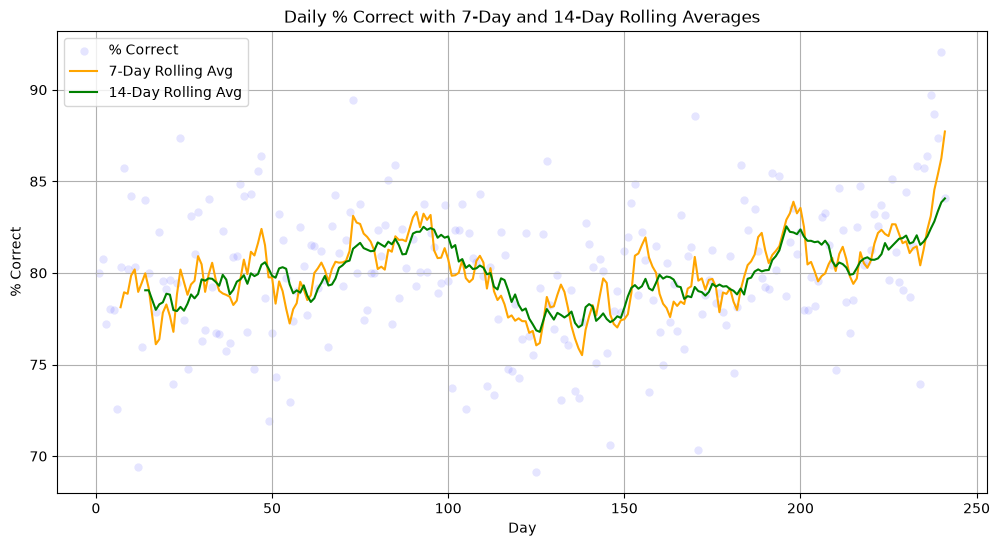

In [71]:
plot_moving_avg(df, outlier_sigma=3)

In [72]:
df.head()

,pass,fail,pct,date,day,pct_rolling_7,pct_rolling_14
0,4,1,80.000000,2025-12-16,1,NaN,NaN
1,21,5,80.769231,2025-12-17,2,NaN,NaN
2,61,18,77.215190,2025-12-19,3,NaN,NaN
3,71,20,78.021978,2025-12-21,4,NaN,NaN
4,39,11,78.000000,2025-12-22,5,NaN,NaN


In [73]:
# Median and mean per day of the week
metric_df = df.groupby(df['date'].dt.day_name()).agg({'pct': ['median', 'mean']}).reset_index()
metric_df["relative_mean"] = (metric_df[('pct', 'mean')] - df["pct"].mean())
# just put 1 digit
metric_df = metric_df.round(1)
metric_df.head(7)

date    pct       relative_mean
             median  mean              
0     Friday   81.5  80.8           0.8
1     Monday   79.5  80.1           0.0
2   Saturday   79.8  80.2           0.2
3     Sunday   80.6  80.4           0.3
4   Thursday   79.4  79.5          -0.5
5    Tuesday   80.4  80.8           0.7
6  Wednesday   79.8  78.8          -1.3

In [74]:
# calculate p value to see if the difference between the means is significant
from scipy import stats

days = df['date'].dt.day_name().unique()
for day in days:
    day_data = df[df['date'].dt.day_name() == day]['pct']
    other_data = df[df['date'].dt.day_name() != day]['pct']
    t_stat, p_value = stats.ttest_ind(day_data, other_data)
    print(f"{day}: p-value = {p_value:.4f}")

Tuesday: p-value = 0.2828
Wednesday: p-value = 0.0423
Friday: p-value = 0.2679
Sunday: p-value = 0.6086
Monday: p-value = 0.9574
Saturday: p-value = 0.7964
Thursday: p-value = 0.4039


# Card clustering

In [75]:
def anki_request(action, **params):
    res = requests.post(ANKI_URL, json={"action": action, "version": 6, "params": params}).json()
    if res.get("error"):
        raise RuntimeError(res["error"])
    return res["result"]

In [76]:
def load_features(DECK_NAME, DAYS_BACK):
    # 1. Load reviews
    cutoff_ms = int((datetime.now() - timedelta(days=DAYS_BACK)).timestamp() * 1000)
    raw_reviews = anki_request("cardReviews", deck=DECK_NAME, startID=cutoff_ms)

    # Group raw review events by card_id
    card_logs = {}
    for entry in raw_reviews:
        # entry: [rev_id, card_id, usn, ease, interval, last_interval, factor, time, type]
        rev_id, cid, _, ease, interval, last_interval, factor, _, _ = entry
        if cid not in card_logs:
            card_logs[cid] = []
        card_logs[cid].append({
            "time": rev_id,
            "pass": 1 if ease > 1 else 0,
            "interval": interval,
            "factor": factor
        })

    # Filter out cards with too few reviews (e.g. at least 4 reviews)
    card_logs = {cid: sorted(logs, key=lambda x: x["time"]) for cid, logs in card_logs.items() if len(logs) >= 4}

    # 2. Extract feature vector per card
    features = []
    for cid, logs in card_logs.items():
        passes = [x["pass"] for x in logs]
        intervals = [x["interval"] for x in logs]
        
        # Feature engineering:
        total_reviews = len(passes)
        pass_rate = np.mean(passes)
        recent_pass_rate = np.mean(passes[-3:])       # Trajectory at the end
        first_pass_rate = np.mean(passes[:2])         # Early acquisition
        final_interval = intervals[-1]                # Current memory stability
        fail_streak = 0
        # count lapses / transitions from 1 -> 0
        lapses = sum(1 for i in range(1, len(passes)) if passes[i-1] == 1 and passes[i] == 0)

        features.append({
            "card_id": cid,
            "total_reviews": total_reviews,
            "pass_rate": pass_rate,
            "recent_pass_rate": recent_pass_rate,
            "first_pass_rate": first_pass_rate,
            "final_interval": final_interval,
            "lapse_rate": lapses / total_reviews
        })

    df_cards = pd.DataFrame(features).set_index("card_id")

    # 3. Pull card front text (Hanzi) for labeling
    card_ids = df_cards.index.tolist()
    cards_info = anki_request("cardsInfo", cards=card_ids)

    card_labels = {}
    for c in cards_info:
        # Gets the first field (usually the Hanzi/Front)
        fields = c.get("fields", {})
        first_field_val = next(iter(fields.values()))["value"] if fields else str(c["cardId"])
        # Strip HTML tags
        card_labels[c["cardId"]] = pd.Series(first_field_val).str.replace(r'<[^>]*>', '', regex=True).iloc[0]

    df_cards["label"] = df_cards.index.map(card_labels)


    # 2. Extract feature vector per card
    features = []
    for cid, logs in card_logs.items():
        passes = [x["pass"] for x in logs]
        intervals = [x["interval"] for x in logs]
        
        # Feature engineering:
        total_reviews = len(passes)
        pass_rate = np.mean(passes)
        recent_pass_rate = np.mean(passes[-3:])       # Trajectory at the end
        first_pass_rate = np.mean(passes[:2])         # Early acquisition
        final_interval = intervals[-1]                # Current memory stability
        fail_streak = 0
        # count lapses / transitions from 1 -> 0
        lapses = sum(1 for i in range(1, len(passes)) if passes[i-1] == 1 and passes[i] == 0)

        features.append({
            "card_id": cid,
            "total_reviews": total_reviews,
            "pass_rate": pass_rate,
            "recent_pass_rate": recent_pass_rate,
            "first_pass_rate": first_pass_rate,
            "final_interval": final_interval,
            "lapse_rate": lapses / total_reviews
        })

    df_cards = pd.DataFrame(features).set_index("card_id")

# 3. Pull card front text (Hanzi) for labeling
    card_ids = df_cards.index.tolist()
    cards_info = anki_request("cardsInfo", cards=card_ids)

    card_labels = {}
    for c in cards_info:
        # Gets the first field (usually the Hanzi/Front)
        fields = c.get("fields", {})
        first_field_val = next(iter(fields.values()))["value"] if fields else str(c["cardId"])
        # Strip HTML tags
        card_labels[c["cardId"]] = pd.Series(first_field_val).str.replace(r'<[^>]*>', '', regex=True).iloc[0]

    df_cards["label"] = df_cards.index.map(card_labels)

    return df_cards

In [77]:
def elbow_and_silhouette(X_scaled, max_k=10):
    from sklearn.metrics import silhouette_score

    wcss = []
    silhouette_scores = []

    for k in range(2, max_k + 1):
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(X_scaled)
        wcss.append(kmeans.inertia_)
        silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

    # Plot WCSS (Elbow Method)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(range(2, max_k + 1), wcss, marker='o')
    plt.title('Elbow Method')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('WCSS')

    # Plot Silhouette Scores
    plt.subplot(1, 2, 2)
    plt.plot(range(2, max_k + 1), silhouette_scores, marker='o', color='orange')
    plt.title('Silhouette Scores')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Silhouette Score')

    # print find elbow point and max silhouette score
    elbow_point = np.diff(wcss).argmin() + 2  # +2 because we start from k=2
    max_silhouette_k = np.argmax(silhouette_scores) + 2  # +2 because we start from k=2
    print(f"Elbow point (k): {elbow_point}")

    print(f"Max silhouette score (k): {max_silhouette_k}")

    plt.tight_layout()
    plt.show()

In [78]:
def visualize_clusters(df_cards, scaler, n_clusters=4):
    X_scaled = scaler.fit_transform(df_cards[["pass_rate", "recent_pass_rate", "first_pass_rate", "final_interval", "lapse_rate"]])
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    df_cards['cluster'] = kmeans.fit_predict(X_scaled)

    # For visualization, we use x and success rate and y a PCA projection of the other features

    pca = PCA(n_components=1)
    X_scaled_no_pass_rate = scaler.fit_transform(df_cards[["recent_pass_rate", "first_pass_rate", "final_interval", "lapse_rate"]])
    pca_projection = pca.fit_transform(X_scaled_no_pass_rate)

    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=df_cards['pass_rate'], y=pca_projection.flatten(), hue=df_cards['cluster'], palette='Set2', s=100, alpha=0.7)

    plt.title(f'Clusters of Cards (n_clusters={n_clusters})')
    plt.xlabel('Pass Rate')
    plt.ylabel('PCA Projection of Other Features')

In [79]:
df_cards = load_features(DECK_NAME, DAYS_BACK)
elbow_and_silhouette(StandardScaler().fit_transform(df_cards[["pass_rate", "recent_pass_rate", "first_pass_rate", "final_interval", "lapse_rate"]]), max_k=20)

KeyboardInterrupt: 

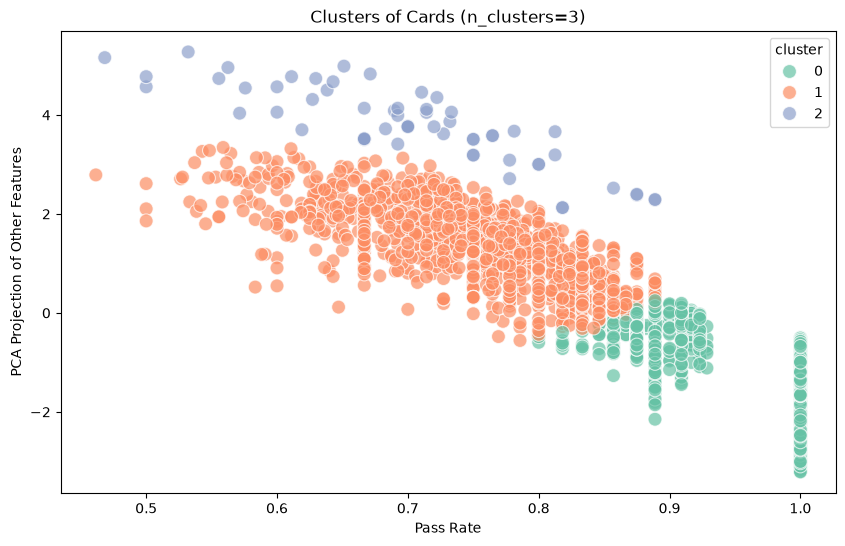

In [ ]:
visualize_clusters(df_cards, StandardScaler(), n_clusters=3)

In [ ]:
# Create a "hardness score" considering pass_rate and total reviews for eahc card
df_cards["hardness_score"] = (1 - df_cards["pass_rate"]) * df_cards["total_reviews"]

<Axes: xlabel='hardness_score', ylabel='Count'>

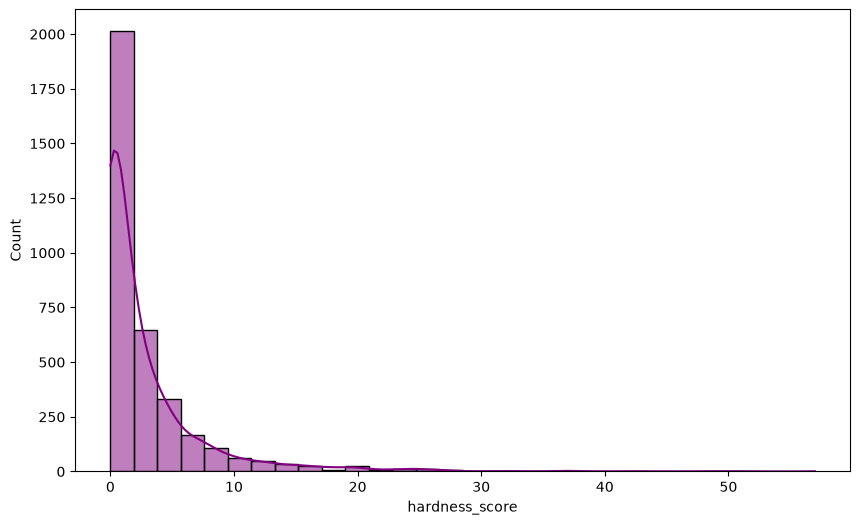

In [ ]:
# Plot hardness score distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_cards["hardness_score"], bins=30, kde=True, color='purple')

In [ ]:
# print sorted cards by hardness score
df_cards.sort_values(by="hardness_score", ascending=False)[["hardness_score", "label", "total_reviews", "pass_rate"]].head(10)  # Show top 10 hardest cards

,hardness_score,label,total_reviews,pass_rate
card_id,,,,
1516347478875,57.0,"abnehmen, nimmt ab, nahm ab, hat abgenommen",138,0.586957
1516347483708,51.0,"die Vorschrift, -en",131,0.610687
1516347478985,51.0,"die Angabe,-n",109,0.532110
1516347479138,49.0,"aufnehmen, nimmt auf, nahm auf, hat aufgenommen",91,0.461538
1516347479131,48.0,"aufheben, hebt auf, hob auf, hat aufgehoben",116,0.586207
1516347479421,45.0,"der Bereich, -e",118,0.618644
1516347484042,42.0,zugehen,93,0.548387
1516347479980,42.0,"einsetzen, setzt ein, setzte ein, hat eingesetzt",79,0.468354
1516347479006,39.0,"die Anmeldung, -en",93,0.580645
